In [1]:
from pathlib import Path
from typing import Callable

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt

from bloodmoon.coords import equatorial2pos, equatorial2shift, shift2angle
from bloodmoon.images import argmax
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.benchmarking import source_catalogue_data, crop_source_psf
from darksun.data import DataLoader, CatalogueLoader

from IROSrec.iros.optim import default_optimiser
from IROSrec.iros.types import OptResult

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
plt.rcdefaults()
mpl.rcParams.update(RCPARAMS)
ds.show.set_figures_darkbkg()

In [2]:
def check_and_pick(parent: Path, pattern: str) -> Path:
    matches = tuple(parent.glob(pattern))
    if not matches:
        raise ValueError(f"A file matching the pattern {str(parent / pattern)} is expected but missing.")
    f, *extra_matches = matches
    if extra_matches:
        raise ValueError(
            f"Found unexpected extra matches for glob pattern {str(parent / pattern)}."
            f"File with pattern {pattern} should be unique"
        )
    return f

def get_source_coords(sourceID: str, catalogue: CatalogueLoader) -> CoordEquatorial:
    """Extracts the source RA/Dec coords from catalogue."""
    data = source_catalogue_data(sourceID, catalogue.DLdata)
    return CoordEquatorial(data['RA'], data['DEC'])

def equatorial2angle(
    sdl: DataLoader,
    camera: CodedMaskCamera,
    ra: float,
    dec: float,
) -> tuple[float, float]:
    """Converts RA/Dec coords to camera local-frame angular coords."""
    shifts = equatorial2shift(sdl, camera, ra, dec)
    return tuple(shift2angle(camera, s) for s in shifts)

def find_boxmax(sky: NDArray, centre: tuple[int, int], boxsize: int = 5) -> tuple[int, int]:
    """Finds the argmax of given sky in a box centered around `pos`."""
    rcut, ccut = map(lambda idx: slice(idx - boxsize, idx + boxsize + 1), centre)
    p, q = centre
    n, m = argmax(sky[rcut, ccut])
    return p - boxsize + n, q - boxsize + m

In [3]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "baseline_2-50keV_1ks"

ID_CAMERA: str = "cam1a"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]

UPS_X, UPS_Y = 2, 1
hide_bulk_els_y: float = 1.5   # [mm]

# BASEDIR: str = "/mnt/dbb8f47e-da06-47bf-8ef5-038092af70f7/Edos_Magnificent_Manor/PhD_AASS/Coding/IROS_Data/Simulations"
BASEDIR: str = "/mnt/d/PhD_AASS/Coding/Images_fits"
DATAPATH: str = Path(f"{BASEDIR}/{SKYFIELD}/{DATA_FITS}")


wfm: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

cat = ds.get_catalogue(check_and_pick(DATAPATH, f'{ID_CAMERA}/*sources*.fits'))
sdl = ds.get_data(check_and_pick(DATAPATH, f'{ID_CAMERA}/*reconstructed*.fits'), E_min=E_min, E_max=E_max)

In [16]:
def config_fitter(
    optimiser: Callable[[NDArray, tuple[int, int]], OptResult],
) -> Callable[[tuple[int, int], NDArray], tuple[NDArray, NDArray]]:
    """
    Configures source candidates parameters fitter.
    """
    def fitter(arg_sky: tuple[int, int], sky: NDArray) -> tuple[NDArray, NDArray]:
        """Performs the optimisation of the source candidate params."""
        try:
            params: OptResult = optimiser(
                sky=sky,
                arg_sky=arg_sky,
            )
        except Exception as e:
            raise RuntimeError(f"Optimization failed: {str(e)}") from e
        
        return params.params, params.covar
    
    return fitter

In [5]:
rot_angle = 0
vignetting = True
psfy = True

In [6]:
srcID = 's17'

mask = (cat.DLdata['NAME'] != srcID)
exclude_srcs: list[CoordEquatorial] = [
    CoordEquatorial(ra, dec) for ra, dec in zip(cat.DLdata['RA'][mask], cat.DLdata['DEC'][mask])
]
phs = ds.filter_data(sdl.DLdata, E_min=None, E_max=None, coords=exclude_srcs)

detector, _ = count(wfm, phs, rot_angle=rot_angle)
skymap = decode(wfm, detector)
varmap = variance(wfm, detector)

/home/starfloyd/PhD_Coding/LearningCodedMasks/newSG/LearningCodedMasks/.venv/lib/python3.12/site-packages/astropy/io/fits/card.py:743: AstropyUserWarning: The following header keyword is invalid or follows an unrecognized non-standard convention:
CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                     
  warnings.warn(


UserInfo: using bulk mask of [0.0 x 1.5] mm.


In [7]:
ra, dec = get_source_coords(srcID, cat)
src_pos = equatorial2pos(sdl, wfm, ra, dec)
src_peak = find_boxmax(skymap, src_pos, boxsize=2 * wfm.upscale_f.x + 1)

In [11]:
rows, cols = crop_source_psf(wfm, src_peak, 2 + wfm.upscale_f.x, 5 * wfm.upscale_f.y)
psfvar = varmap[rows, cols]
fit_weights = np.pow(np.clip(psfvar, a_min=1.0, a_max=None), -0.5).flatten()

In [17]:
optimiser = default_optimiser(
    camera=wfm,
    vignetting=vignetting,
    psfy=psfy,
    fit_weights=fit_weights,
    verbose=True,
)
fit_src_pars = config_fitter(optimiser)

In [18]:
pars, errs = fit_src_pars(src_peak, skymap)


## Optimisation Results:
  * p[0]:
      - START.: -108.3750000
      - OPTIM.: -108.4361279 +/- 0.0002348
      - GAIN.: -0.056 %
  * p[1]:
      - START.: 62.5000000
      - OPTIM.: 62.6740576 +/- 0.0102656
      - GAIN.: 0.278 %
  * p[2]:
      - START.: 824651.8434089
      - OPTIM.: 771318.9482569 +/- 1028.7377412
      - GAIN.: -6.467 %

## Fit Report:
  - func calls (also # of iters): 6
  - procedure msg: Both `ftol` and `xtol` termination conditions are satisfied.
  - success status 4: Convergence in orthogonality



In [20]:
pars, errs

(array([-1.08436128e+02,  6.26740576e+01,  7.71318948e+05]),
 array([2.34821914e-04, 1.02655533e-02, 1.02873774e+03]))

In [ ]:
assert False

In [22]:
def find_tick_val(ticks: NDArray, trg_vals: NDArray, atol: float = 1e-4) -> NDArray:
    """Finds the idxs inside `ticks` relative to given values `trg_vals`."""
    trg_idxs: list[int] = []
    for v in trg_vals:
        idx = np.argwhere(np.isclose(ticks, v, atol=atol))
        if idx.size > 0: trg_idxs.append(idx[0, 0])
    return np.array(trg_idxs)

def set_phase(x: NDArray) -> NDArray:
    """Centers `x` values around zero."""
    return np.arange(len(x) + 1) - len(x) // 2 - 0.5

def get_slices(*arrs: NDArray) -> tuple[tuple[NDArray, ...], tuple[NDArray, ...]]:
    n, m = arrs[0].shape
    xslice, yslice = zip(*tuple((c[(n - 1) // 2, :], c[:, (m - 1) // 2]) for c in arrs))
    return xslice, yslice

def get_heatmap_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
) -> tuple[NDArray, str]:
    """Handles source PSF residuals heatmap to plot."""
    if mode == 'ratio':
        return psf / modelled, 'ratio'

    res = psf - modelled
    if mode == 'res':
        lbl = 'residuals [ph]'
        if express_res_perc:
            res = res * 100 / psf.max()
            lbl = r'residuals [%]'
        return res, lbl

    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))
    return res / sigma, 'residuals [$\\sigma$]'

def get_slices_plot_data(
    psf: NDArray,
    psf_err: NDArray,
    modelled: NDArray,
    modelled_err: NDArray,
    mode: str,
    express_res_perc: bool,
    n_sigma: int,
) -> tuple[NDArray, NDArray, str]:
    """
    Handles data to plot from source PSF and sigma slices, for both true and modelled.
    """
    if mode not in ('res', 'ratio', 'sigma'):
        raise ValueError(f"Invalid input mode '{mode}'.")
    
    if mode == 'ratio':
        sigma = psf_err / np.abs(modelled) + np.abs(psf / np.square(modelled)) * modelled_err
        return psf / modelled, n_sigma * sigma, 'ratio'

    res = psf - modelled
    sigma = np.sqrt(np.square(psf_err) + np.square(modelled_err))

    if mode == 'res':
        lbl = 'residuals [counts]'
        if express_res_perc:
            res, sigma = map(lambda x: x * 100 / psf.max(), (res, sigma))
            lbl = r'residuals [%]'
        return res, n_sigma * sigma, lbl

    return res / sigma, n_sigma * np.ones_like(res), 'residuals [$\\sigma$]'

def show_PSF_total(
    camera: CodedMaskCamera,
    true_w_err: tuple[NDArray, NDArray],
    modelled_w_err: tuple[NDArray, NDArray],
    save_to: str | None = None,
    express_res_perc: bool = True,
    express_res_sigma: bool = False,
    n_sigma: int = 1,
    cts_lims: tuple = (None, None),
    hm_ratio_lims: tuple = (None, None),
    fine_ratio_lims: tuple = (None, None),
    coarse_ratio_lims: tuple = (None, None),
    save_options: dict | None = None,
    **fig_kws,
) -> None:
    """
    Plots the source PSF heat maps and profiles along fine/coarse axes + cfr with modelled source.
    """
    res_mode = 'res'
    if express_res_sigma:
        express_res_perc = False
        res_mode = 'sigma'

    title_fs = 16
    lbl_fs = 14
    
    dtx, dty = ds.pixels_angular_resolution(camera, verbose=False)
    psf, modelled = true_w_err[0], modelled_w_err[0]
    psf_xslice, psf_yslice = get_slices(*true_w_err)
    modelled_xslice, modelled_yslice = get_slices(*modelled_w_err)

    phase_fine, phase_coarse = (
        dtx * set_phase(psf_xslice[0]),
        dty * set_phase(psf_yslice[0]) / 60,
    )
    phase_ferr, phase_cerr = (
        dtx * (set_phase(psf_xslice[0])[:-1] + 0.5),
        dty * (set_phase(psf_yslice[0])[:-1] + 0.5) / 60,
    )
    
    slice_clrs = ('OrangeRed', 'DodgerBlue')
    img_factory = dict(origin='lower', interpolation='none', aspect=2 * psf.shape[1] / psf.shape[0])
    errbar_factory = dict(linestyle='', elinewidth=0.7, capsize=0)

    fig, axs = plt.subplots(3, 3, tight_layout=True, **fig_kws)
    axs = axs.flatten()

    # ------------------------ 1st ROW (PSF HM + Profiles f/c) ---------------------------
    slice_lim_vals = max(modelled.max(), psf.max())
    slice_lim_vals = (cts_lims[0] or -0.075 * slice_lim_vals, cts_lims[1] or 1.05 * slice_lim_vals)
    
    axs[0].set_title('Crab PSF', fontsize=title_fs)
    psf_img = axs[0].imshow(psf, cmap='gist_heat', vmin=cts_lims[0], vmax=cts_lims[1], **img_factory)
    cbar = fig.colorbar(psf_img, ax=axs[0], location='right', shrink=0.8, pad=0.05)
    cbar.set_label('counts', fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[0].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[0].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[1].set_title('PSF Slice - Fine Axis', fontsize=title_fs)
    axs[1].stairs(psf_xslice[0], edges=phase_fine, edgecolor=slice_clrs[0], label='true')
    axs[1].stairs(modelled_xslice[0], edges=phase_fine, edgecolor=slice_clrs[1], label='modelled')
    axs[1].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[2].set_title('PSF Slice - Coarse Axis', fontsize=title_fs)
    axs[2].stairs(psf_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[0], label='true')
    axs[2].stairs(modelled_yslice[0], edges=phase_coarse, edgecolor=slice_clrs[1], label='modelled')
    axs[2].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[2].set_ylabel(ylabel='counts', labelpad=10, fontsize=lbl_fs)

    for idx in [1, 2]: axs[idx].set_ylim(slice_lim_vals)

    # ------------------------ 2nd ROW (RES [%] HM + Profiles f/c) ------------------------    
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, res_mode, express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, res_mode, express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, res_mode, express_res_perc, n_sigma)

    axs[3].set_title(f'Crab PSF Residuals', fontsize=title_fs)
    mod_img = axs[3].imshow(psf_hm_res, **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[3], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[3].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[3].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[4].set_title(f'PSF Slice Residuals - Fine Axis', fontsize=title_fs)
    axs[4].plot(phase_fine, np.zeros_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[4].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[4].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[4].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[5].set_title(f'PSF Slice Residuals - Coarse Axis', fontsize=title_fs)
    axs[5].plot(phase_coarse, np.zeros_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[5].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[5].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[5].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[5].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ------------------------ 3rd ROW (RATIO HM + Profiles f/c) --------------------------
    psf_hm_res, hm_lbl = get_heatmap_plot_data(*true_w_err, *modelled_w_err, 'ratio', express_res_perc)
    xres, xsigma, lbl = get_slices_plot_data(*psf_xslice, *modelled_xslice, 'ratio', express_res_perc, n_sigma)
    yres, ysigma, _ = get_slices_plot_data(*psf_yslice, *modelled_yslice, 'ratio', express_res_perc, n_sigma)

    vlim = max(np.abs(xres).max(), np.abs(yres).max())
    hm_res_lims_ = (hm_ratio_lims[0] or -vlim + 1, hm_ratio_lims[1] or vlim + 1)

    axs[6].set_title(f'Crab PSF Ratio', fontsize=title_fs)
    mod_img = axs[6].imshow(psf_hm_res, vmin=hm_res_lims_[0], vmax=hm_res_lims_[1], **img_factory)
    cbar = fig.colorbar(mod_img, ax=axs[6], location='right', shrink=0.8, pad=0.05)
    cbar.set_label(hm_lbl, fontsize=lbl_fs)
    cbar.ax.tick_params(labelsize=lbl_fs)
    axs[6].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)
    axs[6].set_ylabel(ylabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)

    axs[7].set_title(f'PSF Slice Ratio - Fine Axis', fontsize=title_fs)
    axs[7].plot(phase_fine, np.ones_like(phase_fine), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[7].stairs(xres, edges=phase_fine, edgecolor=slice_clrs[1], label=lbl)
    axs[7].errorbar(phase_ferr, xres, c=slice_clrs[1], yerr=xsigma, marker='', **errbar_factory)
    axs[7].set_ylim(fine_ratio_lims)
    axs[7].set_xlabel(xlabel='$\\Delta\\theta_{fine}$ [arcmin]', fontsize=lbl_fs)

    axs[8].set_title(f'PSF Slice Ratio - Coarse Axis', fontsize=title_fs)
    axs[8].plot(phase_coarse, np.ones_like(phase_coarse), slice_clrs[0], label='ground', linestyle='--', alpha=0.6)
    axs[8].stairs(yres, edges=phase_coarse, edgecolor=slice_clrs[1], label=lbl)
    axs[8].errorbar(phase_cerr, yres, c=slice_clrs[1], yerr=ysigma, marker='', **errbar_factory)
    axs[8].set_ylim(coarse_ratio_lims)
    axs[8].set_xlabel(xlabel='$\\Delta\\theta_{coarse}$ [deg]', fontsize=lbl_fs)
    axs[8].set_ylabel(ylabel=lbl + f" (C.L. ${n_sigma}\\sigma$)", labelpad=10, fontsize=lbl_fs)

    # ticks for HMs
    yticks, xticks = map(lambda s: np.arange(0, s), psf.shape)
    _ytick_lbls, _xtick_lbls = (
        dty / 60 * (yticks - len(yticks) // 2), dtx * (xticks - len(xticks) // 2),
    )
    yticks_ = find_tick_val(_ytick_lbls, np.array([-5.0, -2.5, 0.0, 2.5, 5.0]), atol=7e-2)
    yticks_lbl = [float(f'{t:.1f}') for t in _ytick_lbls[yticks_]]
    xticks_ = find_tick_val(_xtick_lbls, np.array([-5.0, 0.0, 5.0]), atol=1e-1)
    xticks_lbl = [float(f'{t:.1f}') for t in _xtick_lbls[xticks_]]

    for idx in [0, 3, 6]:
        axs[idx].set_xticks(xticks_, xticks_lbl)
        axs[idx].set_yticks(yticks_, yticks_lbl)
    
    for idx in [1, 2, 4, 5, 7, 8]:
        axs[idx].yaxis.tick_right()
        axs[idx].legend(loc='best')

    for idx in [2, 5, 8]:
        axs[idx].yaxis.set_label_position('right')

    for idx, ax in enumerate(axs):
        ax.xaxis.set_ticks_position('both')
        ax.yaxis.set_ticks_position('both')
        ax.tick_params(which='both', direction='in', width=1.5, length=4 if 'major' else 2.5, labelsize=lbl_fs)

    if save_to is not None:
        save_options_ = save_options or {}
        fig.savefig(save_to, **save_options_)
    
    plt.show()
    return

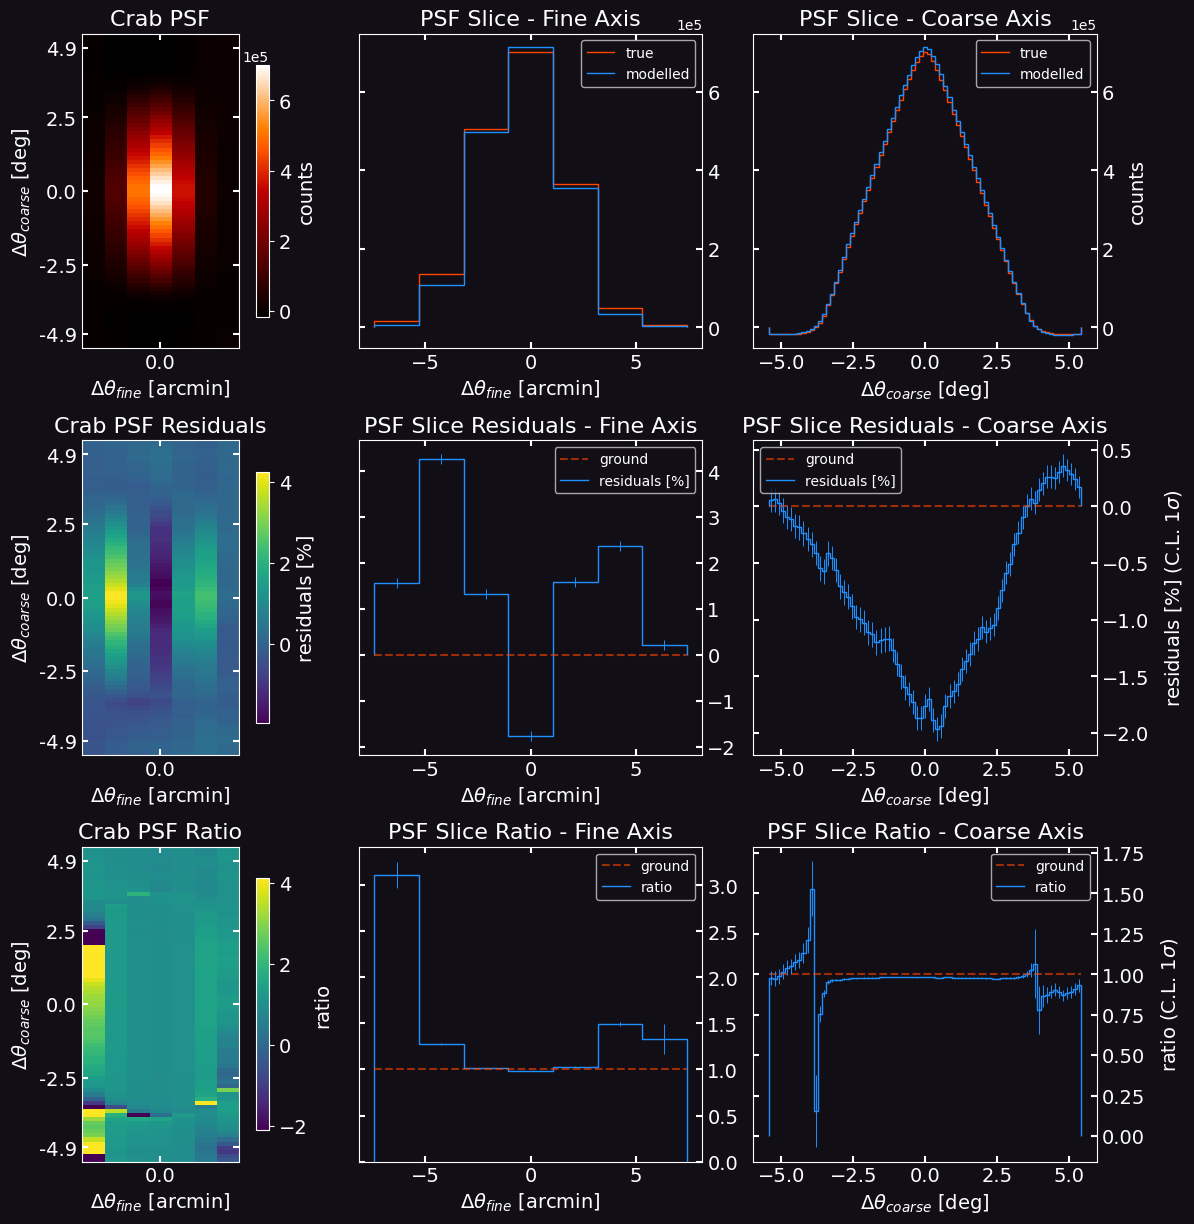

In [24]:
from bloodmoon.optim import model_sky

sky_model = model_sky(wfm, *pars, vignetting=vignetting, psfy=psfy)
var_model = np.zeros_like(sky_model)

get_cropped = lambda x: ds.crop(x, src_peak, (38 * UPS_Y, 2 * (UPS_X - 1) + 1))
psf_true, psf_var = map(get_cropped, (skymap, varmap))
psf_model, psf_model_var = map(get_cropped, (sky_model, var_model))

show_PSF_total(
    camera=wfm,
    true_w_err=(psf_true, np.sqrt(psf_var)),
    modelled_w_err=(psf_model, np.zeros_like(psf_model)),  # NOTE: [validate sg error consistency] np.sqrt(psf_model_var)
    express_res_perc=True,
    # express_res_sigma=True,
    n_sigma=1,
    figsize=(4 * 3 + 0.5, 4 * 3 + 0.5),
)